# Étape 6 – Détection des sujets émergents

**Question centrale** : quels mots, expressions et thèmes **prennent soudainement de l'importance** dans la presse lyonnaise, lesquels s'installent, lesquels disparaissent ?
Et surtout : comment ne pas confondre un sujet **émergent** avec un sujet simplement **très fréquent** ?

## Méthode (simple et explicable)
- **Pas de temps : la semaine** (13 semaines complètes, du 3 août au 1er novembre). Les séries journalières ont un cycle de 7 jours (Lyon Capitale publie moitié moins le week-end, voir notebook 03).
- **Unité : la part de titres contenant le terme** (lemme ou bigramme), pas un comptage brut : elle ne dépend pas du volume de la semaine.
- **Composition par média neutralisée** : la part est calculée *par média* puis recombinée avec des poids fixes (parts moyennes : Le Progrès 45 %, Lyon Capitale 38 %, LyonMag 17 %). Sans cela, la panne GDELT du Progrès (semaine du 12 octobre) ferait varier les thèmes à elle seule. BFM Lyon (78 articles) n'entre pas dans les séries.
- **Score d'émergence** : pour une semaine *t*, z = (part de la semaine − part moyenne des 4 semaines précédentes) / écart-type, avec l'écart-type binomial de la semaine **et** de la période de base. Un plancher évite un score infini pour un terme absent du passé.
- **Critères de détection** (pour limiter les fausses alertes, car ≈ 1 400 termes × 9 semaines sont testés) : z ≥ 4, **au moins 6 titres** la semaine du pic, présence dans **au moins 2 médias** (un événement est couvert par plusieurs rédactions ; cela écarte les artefacts de format d'un seul média).
- **Regroupement** : les termes d'une même semaine dont les titres se recoupent à plus de 60 % (« raphaël arnault », « arnault », « raphaël ») sont fusionnés.
- **Trajectoire** : *montée durable* si une des 2 semaines suivantes garde au moins la moitié de l'excès, *pic ponctuel* sinon, *indéterminé* si le pic est trop près de la fin.

Le z n'est **pas une p-valeur calibrée** (les titres d'un même événement sont corrélés, la loi binomiale sous-estime la variance) ; c'est un **indice de classement**. On le complète par une lecture des titres et une analyse de sensibilité.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
MEDIA_ORDER = ["Le Progrès", "Lyon Capitale", "LyonMag", "BFM Lyon"]
MEDIA_COLORS = dict(zip(MEDIA_ORDER, sns.color_palette("deep")[:4]))

from scipy import stats
from scipy.sparse import csr_matrix
from src.preprocessing.text_cleaning import add_token_columns
from src.analysis import emergence as E

corpus = pd.read_parquet(ROOT / "data" / "processed" / "corpus.parquet")
df = add_token_columns(corpus[corpus["in_analysis"]]).reset_index(drop=True)
df = df[df.media_name.isin(E.MAIN_MEDIA)].reset_index(drop=True)
sets = E.term_sets(df.tokens_raw, df.tokens_lemma)
B, terms = E.binary_matrix(sets, min_df=6)
weeks = sorted(df.week_start.unique()); week_labels = [pd.Timestamp(w).strftime("%d %b") for w in weeks]
counts, n = E.weekly_counts(B, df, weeks); pi = E.media_weights(df)
LOW_W = list(weeks).index(np.datetime64("2026-10-12"))          # semaine de la panne GDELT du Progrès
print(f"{len(df):,} titres, {len(weeks)} semaines, {B.shape[1]:,} termes (lemmes + bigrammes présents dans ≥ 6 titres)")
print("Poids des médias :", dict(zip(E.MAIN_MEDIA, pi.round(3))))
print("Titres par média et par semaine :"); display(pd.DataFrame(n.astype(int), index=E.MAIN_MEDIA, columns=week_labels))

4,858 titres, 13 semaines, 1,391 termes (lemmes + bigrammes présents dans ≥ 6 titres)
Poids des médias : {'Le Progrès': np.float64(0.447), 'Lyon Capitale': np.float64(0.382), 'LyonMag': np.float64(0.171)}
Titres par média et par semaine :


,03 Aug,10 Aug,17 Aug,24 Aug,31 Aug,07 Sep,14 Sep,21 Sep,28 Sep,05 Oct,12 Oct,19 Oct,26 Oct
Le Progrès,141,153,172,167,166,175,195,197,179,154,118,182,172
Lyon Capitale,116,128,110,129,147,149,157,150,162,169,141,149,148
LyonMag,51,62,57,45,58,59,58,77,73,54,90,76,72


## 1. Fréquent n'est pas émergent
Un mot très fréquent comme « homme » ou « blessé » est présent toutes les semaines : il a un fort effectif mais un score d'émergence faible. À l'inverse, « couvre-feu » est rare sur la période mais jaillit en une semaine.
Le graphique oppose, pour chaque terme, sa **fréquence totale** et son **score d'émergence maximal**.

,terme,titres (période),z max
0,homme,158,2.1
1,villeurbanne,141,2.1
2,blessé,115,2.6
3,euro,110,1.4
4,métropole,108,4.8
5,lycéen,106,24.2
6,incendie,105,1.9
7,violence,104,3.2
8,manifestation,103,9.9
9,personne,102,1.9


Corrélation de rang (Spearman) entre fréquence et score d'émergence maximal : -0.20


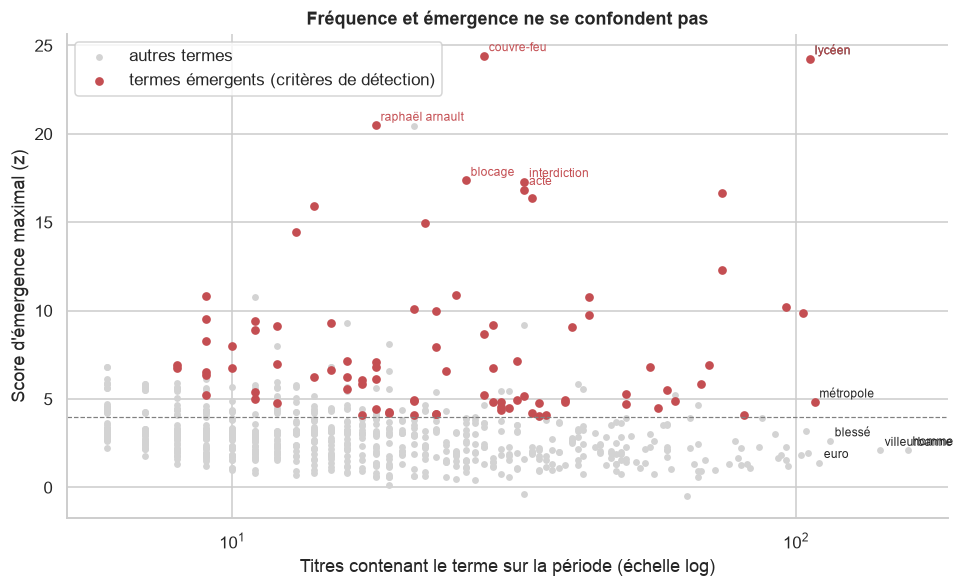

In [2]:
z_all, p_all, p0_all = E.emergence_scores(counts, n, pi)
tot = counts.sum(axis=(0, 1)); wk_tot = counts.sum(axis=0)
z_max = np.nanmax(np.where(wk_tot >= 3, z_all, np.nan), axis=0)            # au moins 3 titres la semaine du pic
events, _ = E.detect_events(counts, n, pi, terms, B, df, weeks)
lead = set(events.t)
freq_vs_em = pd.DataFrame({"terme": terms, "titres (période)": tot.astype(int), "z max": z_max})
top_freq = freq_vs_em.sort_values("titres (période)", ascending=False).head(12)
display(top_freq.round(1).reset_index(drop=True))
print(f"Corrélation de rang (Spearman) entre fréquence et score d'émergence maximal : {stats.spearmanr(freq_vs_em['titres (période)'], freq_vs_em['z max'], nan_policy='omit')[0]:.2f}")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(tot, z_max, s=12, color="lightgrey", label="autres termes")
em = np.array(sorted(lead)); ax.scatter(tot[em], z_max[em], s=22, color=sns.color_palette()[3], label="termes émergents (critères de détection)")
for i in top_freq.index[:6]: ax.annotate(terms[i], (tot[i], z_max[i]), fontsize=8, xytext=(3, 3), textcoords="offset points")
for t in events.head(6).t: ax.annotate(terms[t], (tot[t], z_max[t]), fontsize=8, color=sns.color_palette()[3], xytext=(3, 3), textcoords="offset points")
ax.axhline(4, color="grey", ls="--", lw=0.8); ax.set(xscale="log", title="Fréquence et émergence ne se confondent pas", xlabel="Titres contenant le terme sur la période (échelle log)", ylabel="Score d'émergence maximal (z)")
ax.legend(); plt.tight_layout(); fig.savefig(FIG / "06_frequent_vs_emergent.png", bbox_inches="tight"); plt.show()

## 2. Les sujets émergents détectés
**Annotation manuelle** : pour les 32 premiers résultats, nous avons lu les titres du pic et noté l'événement qu'ils désignent (colonne *événement*). C'est la seule « vérité terrain » dont nous disposons ; elle permet de mesurer la précision de la méthode.

In [3]:
EVENT = {  # événement identifié en lisant les titres du pic ; None = aucun événement identifiable (faux positif)
 "couvre-feu": "Émeutes du 17 oct. : couvre-feu en Presqu'île", "interdiction": "Émeutes du 17 oct. : couvre-feu / rassemblements interdits",
 "pillage": "Émeutes du 17 oct. : pillages", "émeute": "Émeutes du 17 oct.", "commerçant": "Émeutes du 17 oct. : aides aux commerçants",
 "commerce": "Émeutes du 17 oct. : commerces touchés", "presqu île": "Émeutes du 17 oct. : Presqu'île",
 "acte": "« Acte II » (24 oct.) après les émeutes", "acte iii": "« Acte III » Gilets jaunes (31 oct.)",
 "lycéen": "Mouvement lycéen : blocages, affrontements", "blocage": "Mouvement lycéen : blocages", "mobilisation": "Mouvement lycéen : mobilisation",
 "lycée": "Mouvement lycéen", "tension": "Mouvement lycéen : tensions devant les lycées", "mouvement lycéen": "Mouvement lycéen",
 "mobilisation lycéenne": "Mouvement lycéen", "manifestation": "Manifestations lycéennes (6 oct., Bellecour)", "établissement": "Mouvement lycéen (partiel)",
 "raphaël arnault": "Affaire Quentin Deranque : audition de R. Arnault", "député": "Affaire Quentin Deranque : audition de R. Arnault",
 "trappe": "Attentat de Trappes et hommages", "halloween": "Halloween (agenda de sorties)", "municipal": "Recours contre les municipales (Aulas, Vénissieux)",
 "élection": "Recours contre des élections municipales", "échevin": "Vœu des Échevins (8 sept.)", "warren": "Procès Iris et Warren",
 "vacance": "Vacances de la Toussaint", "coen": "Festival Lumière : frères Coen", "visiter": "Visite de la commission du CIO (JO 2030)",
 "equita": "Salon équestre Equita Lyon", "art contemporain": "Biennale d'art contemporain", "chef": None,
}
def example_title(t, w):
    rows = [i for i in B.tocsc()[:, t].indices if df.week_start[i] == weeks[w]]
    return df.title_clean[rows[0]][:95]
ev = events.copy()
ev["exemple de titre"] = [example_title(t, w) for t, w in zip(ev.t, ev.w)]
ev["événement (annotation manuelle)"] = ev.terme.map(EVENT)
ev["part avant (%)"] = (100 * ev["part avant"]).round(2); ev["part au pic (%)"] = (100 * ev["part au pic"]).round(1); ev["z"] = ev["z"].round(1)
ev["confiance"] = np.where(ev.semaine == pd.Timestamp("2026-10-12"), "faible (semaine à couverture dégradée)", "normale")
cols = ["semaine", "terme", "termes associés", "titres au pic", "part avant (%)", "part au pic (%)", "z", "médias", "trajectoire", "événement (annotation manuelle)", "exemple de titre", "confiance"]
ev[cols].to_csv(TAB / "06_evenements_emergents.csv", index=False)
print(f"{len(ev)} termes émergents après regroupement (z ≥ 4, ≥ 6 titres, ≥ 2 médias)")
print("Par semaine :", ev.groupby(ev.semaine.dt.strftime("%d %b")).size().to_dict()); print("Trajectoires :", ev.trajectoire.value_counts().to_dict())
top32 = ev.head(32); known = top32["événement (annotation manuelle)"].notna()
print(f"\nPrécision sur les 32 premiers (lecture des titres) : {known.sum()}/32 correspondent à un événement identifiable ; faux positif : {list(top32[~known].terme)}")
print(f"Ces 32 termes se rattachent à {top32.loc[known, 'événement (annotation manuelle)'].str.split(' : | \\(').str[0].nunique()} « familles » d'événements (un événement génère plusieurs termes).")
pd.set_option("display.max_colwidth", 60)
display(ev[cols].drop(columns=["exemple de titre", "confiance"]).head(32))

87 termes émergents après regroupement (z ≥ 4, ≥ 6 titres, ≥ 2 médias)
Par semaine : {'05 Oct': 7, '07 Sep': 9, '12 Oct': 9, '14 Sep': 7, '19 Oct': 17, '21 Sep': 6, '26 Oct': 9, '28 Sep': 12, '31 Aug': 11}
Trajectoires : {'pic ponctuel': 34, 'montée durable': 27, 'indéterminé (fin de période)': 26}

Précision sur les 32 premiers (lecture des titres) : 31/32 correspondent à un événement identifiable ; faux positif : ['chef']
Ces 32 termes se rattachent à 17 « familles » d'événements (un événement génère plusieurs termes).


,semaine,terme,termes associés,titres au pic,part avant (%),part au pic (%),z,médias,trajectoire,événement (annotation manuelle)
0,2026-10-19,couvre-feu,,21,0.13,5.1,24.4,3,indéterminé (fin de période),Émeutes du 17 oct. : couvre-feu en Presqu'île
1,2026-09-28,lycéen,,24,0.18,5.8,24.2,3,montée durable,"Mouvement lycéen : blocages, affrontements"
2,2026-10-26,raphaël arnault,"arnault, raphaël",17,0.13,4.3,20.5,3,indéterminé (fin de période),Affaire Quentin Deranque : audition de R. Arnault
3,2026-09-28,blocage,,14,0.12,3.5,17.4,3,pic ponctuel,Mouvement lycéen : blocages
4,2026-10-19,interdiction,,18,0.19,4.4,17.3,3,indéterminé (fin de période),Émeutes du 17 oct. : couvre-feu / rassemblements interdits
5,2026-10-19,acte,,18,0.21,4.5,16.9,3,indéterminé (fin de période),« Acte II » (24 oct.) après les émeutes
6,2026-09-28,mobilisation,,18,0.20,4.3,16.7,3,montée durable,Mouvement lycéen : mobilisation
7,2026-10-19,pillage,,23,0.33,5.6,16.4,3,indéterminé (fin de période),Émeutes du 17 oct. : pillages
8,2026-10-26,trappe,attentat,13,0.13,3.3,15.9,3,indéterminé (fin de période),Attentat de Trappes et hommages
9,2026-10-19,émeute,,15,0.19,3.8,14.9,2,indéterminé (fin de période),Émeutes du 17 oct.


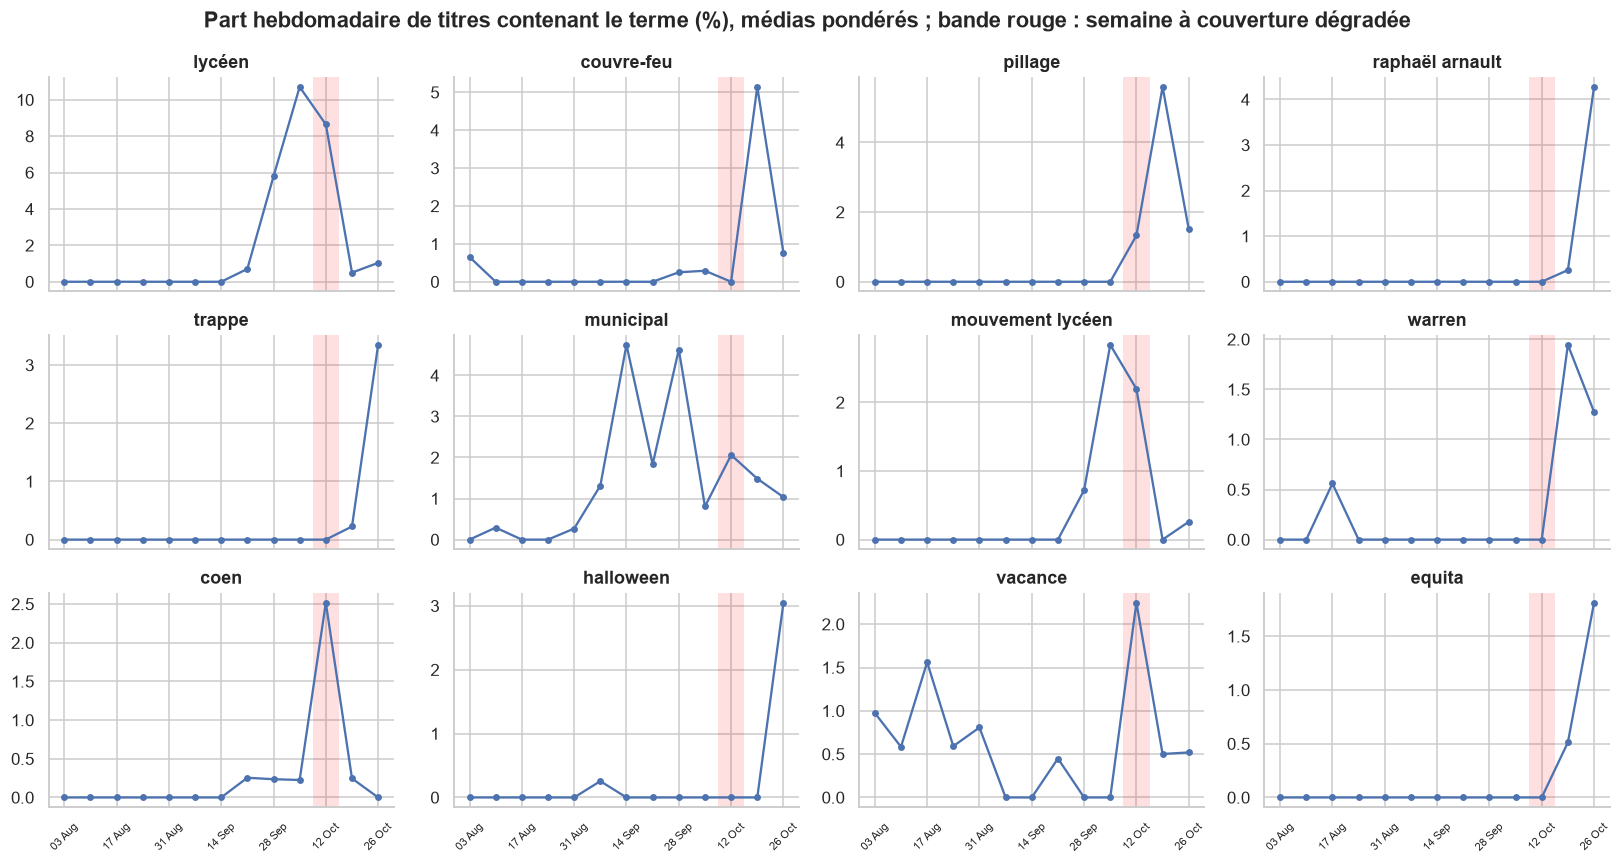

In [4]:
# Série hebdomadaire de 12 termes émergents (un par événement principal) : la part (%) de titres, médias recombinés
lead_terms = ["lycéen", "couvre-feu", "pillage", "raphaël arnault", "trappe", "municipal", "mouvement lycéen", "warren", "coen", "halloween", "vacance", "equita"]
idx = {t: i for i, t in enumerate(terms)}
fig, axes = plt.subplots(3, 4, figsize=(15, 8), sharex=True)
for ax, term in zip(axes.ravel(), lead_terms):
    t = idx[term]
    ax.plot(range(len(weeks)), 100 * p_all[:, t], marker="o", ms=3.5, color=sns.color_palette()[0])
    ax.axvspan(LOW_W - 0.5, LOW_W + 0.5, color="red", alpha=0.12, lw=0)
    ax.set(title=term, xticks=range(0, len(weeks), 2)); ax.set_xticklabels([week_labels[i] for i in range(0, len(weeks), 2)], rotation=45, fontsize=7)
fig.suptitle("Part hebdomadaire de titres contenant le terme (%), médias pondérés ; bande rouge : semaine à couverture dégradée", fontweight="bold")
plt.tight_layout(); fig.savefig(FIG / "06_series_termes_emergents.png", bbox_inches="tight"); plt.show()

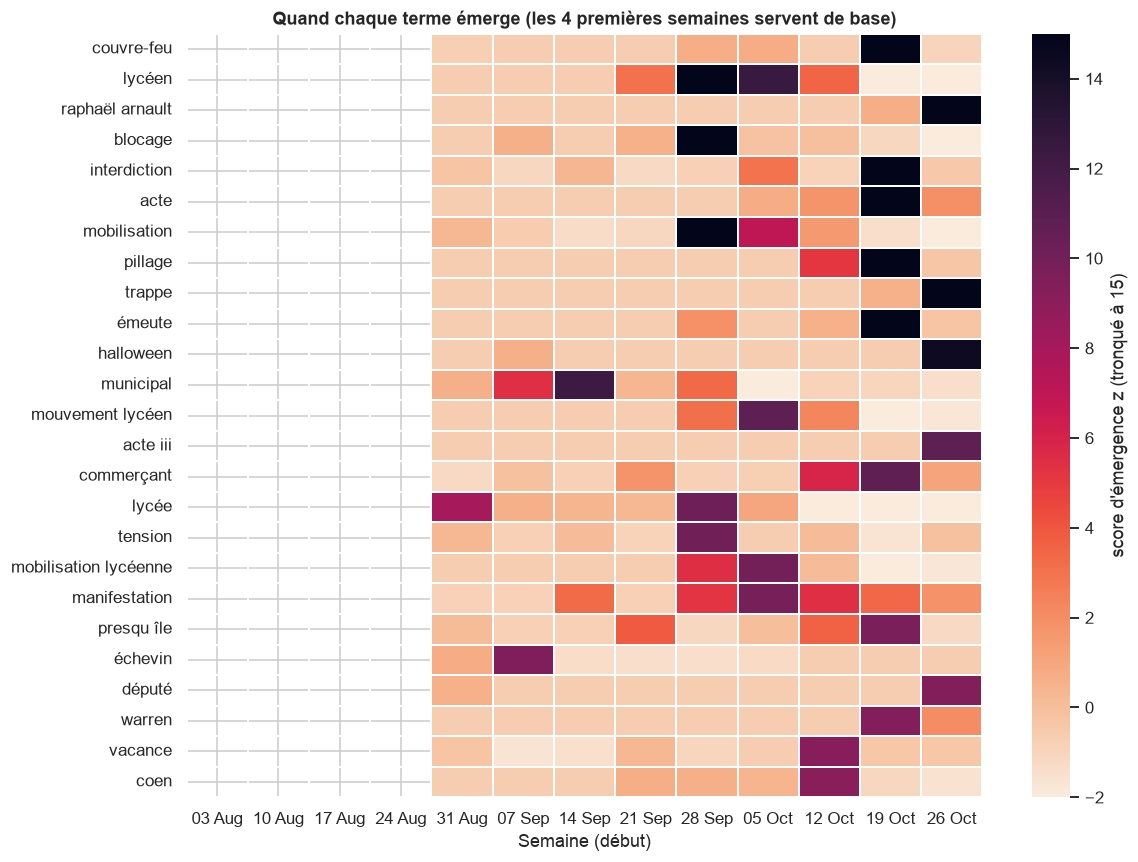

In [5]:
# Heatmap des scores z pour les 25 premiers termes émergents
top_t = list(events.head(25).t)
Hm = pd.DataFrame(z_all[:, top_t].T, index=[terms[t] for t in top_t], columns=week_labels)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(Hm.clip(-2, 15), cmap="rocket_r", ax=ax, cbar_kws={"label": "score d'émergence z (tronqué à 15)"}, linewidths=0.3, linecolor="white")
ax.set(title="Quand chaque terme émerge (les 4 premières semaines servent de base)", xlabel="Semaine (début)", ylabel="")
plt.tight_layout(); fig.savefig(FIG / "06_heatmap_emergence.png", bbox_inches="tight"); plt.show()

## 3. Sujets en déclin
Un déclin est **progressif** : comparer chaque semaine aux 4 précédentes ne le détecte presque jamais (un seul terme, « lycéen », juste après son pic). On compare donc la **part moyenne des 4 premières semaines** (3 août – 30 août)
à celle des **4 dernières** (5 oct. – 1er nov.), avec le même z (variance binomiale des deux périodes), pour les termes présents dans au moins 15 titres au début.

In [6]:
first, last = slice(0, 4), slice(len(weeks) - 4, len(weeks))
p_first, p_last = p_all[first].mean(axis=0), p_all[last].mean(axis=0)
n_first, n_last = n[:, first].sum(axis=1), n[:, last].sum(axis=1)
pi_ = pi[:, None]
pm = np.maximum((p_first + p_last) / 2, 1e-6)
var = (E.binom_var(pm, n_first / 4, pi) / 4 + E.binom_var(pm, n_last / 4, pi) / 4)          # variance des deux moyennes de 4 semaines
z_dec = (p_last - p_first) / np.sqrt(var)
titles_first = counts[:, first, :].sum(axis=(0, 1))
dec = pd.DataFrame({"terme": terms, "titres début": titles_first.astype(int), "titres fin": counts[:, last, :].sum(axis=(0, 1)).astype(int),
                    "part début (%)": (100 * p_first).round(2), "part fin (%)": (100 * p_last).round(2), "z": z_dec.round(1)})
dec = dec[(dec["titres début"] >= 15) & (dec.z <= -4)].sort_values("z")
rise = pd.DataFrame({"terme": terms, "titres début": titles_first.astype(int), "titres fin": counts[:, last, :].sum(axis=(0, 1)).astype(int),
                     "part début (%)": (100 * p_first).round(2), "part fin (%)": (100 * p_last).round(2), "z": z_dec.round(1)})
rise = rise[(rise["titres fin"] >= 15) & (rise.z >= 4)].sort_values("z", ascending=False)
dec.to_csv(TAB / "06_termes_en_declin.csv", index=False); rise.to_csv(TAB / "06_termes_en_hausse_debut_fin.csv", index=False)
print(f"Déclin début → fin : {len(dec)} termes (z ≤ −4, ≥ 15 titres au début) ; hausse : {len(rise)} termes")
print("\nEn déclin :"); display(dec.head(15).reset_index(drop=True))
print("En hausse (début → fin de période) :"); display(rise.head(10).reset_index(drop=True))

Déclin début → fin : 12 termes (z ≤ −4, ≥ 15 titres au début) ; hausse : 23 termes

En déclin :


,terme,titres début,titres fin,part début (%),part fin (%),z
0,canicule,43,5,3.33,0.38,-5.8
1,vigilance,40,8,3.17,0.51,-5.3
2,orage,35,6,2.70,0.38,-5.0
3,rentrée,24,2,1.82,0.13,-4.6
4,éclipse,20,0,1.50,0.00,-4.6
5,forêt,24,3,1.91,0.19,-4.5
6,vigilance orange,18,0,1.43,0.00,-4.5
7,noyade,18,0,1.36,0.00,-4.4
8,beaujolais,39,11,2.86,0.70,-4.3
9,feu,43,15,3.30,0.99,-4.2


En hausse (début → fin de période) :


,terme,titres début,titres fin,part début (%),part fin (%),z
0,manifestation,3,91,0.23,6.01,8.8
1,lycéen,0,79,0.00,5.22,8.7
2,pillage,0,34,0.00,2.11,5.5
3,mobilisation,5,48,0.42,3.17,5.5
4,acte,2,31,0.15,1.98,4.7
5,violence,10,53,0.74,3.16,4.7
6,presqu île,3,34,0.21,2.13,4.7
7,presqu,3,34,0.21,2.13,4.7
8,île,3,34,0.21,2.13,4.7
9,doucet,5,40,0.39,2.38,4.5


**Lecture prudente.** Les déclins sont pour l'essentiel des **sujets estivaux** (canicule, orage, vigilance, éclipse, noyade, vendanges, Beaujolais) : ils s'effacent parce que la saison change, pas forcément parce que la rédaction les abandonne.
« Fusillade » (20 → 1 titre) est une exception non saisonnière. À l'inverse, les termes en hausse (manifestation, lycéen, pillage, mobilisation, violence, Doucet) sont ceux des événements d'octobre. Sur 13 semaines, on ne peut pas distinguer un déclin éditorial d'un cycle saisonnier ; il faudrait au moins une année de données.

## 4. Évolution des thèmes (K-Means, notebook 05)

In [7]:
topics = pd.read_parquet(ROOT / "data" / "processed" / "article_topics.parquet")[["article_id", "km", "km_label"]]
dt = df.merge(topics, on="article_id", how="inner").reset_index(drop=True)
K = int(dt.km.max()) + 1
lab = dt.drop_duplicates("km").set_index("km")["km_label"].sort_index().to_dict()
Bk = csr_matrix(np.eye(K)[dt.km.values])
c_k, n_k = E.weekly_counts(Bk, dt, weeks)
p_k = 100 * E.balanced_share(c_k, n_k, E.media_weights(dt))                     # [semaine, thème] en % des titres, médias pondérés
z_k, _, _ = E.emergence_scores(c_k, n_k, E.media_weights(dt))
trend = []
for k in range(K):
    rho, pv = stats.spearmanr(range(len(weeks)), p_k[:, k]); slope = stats.linregress(range(len(weeks)), p_k[:, k]).slope
    cls = "en hausse" if (rho >= 0.6 and pv < 0.05) else "en baisse" if (rho <= -0.6 and pv < 0.05) else "stable / irrégulier"
    trend.append({"cluster": k, "thème": lab[k], "part moyenne (%)": round(p_k[:, k].mean(), 1), "pente (pt/semaine)": round(slope, 2), "ρ de Spearman": round(rho, 2), "p": round(pv, 3),
                  "tendance": cls, "pic (semaine)": week_labels[int(np.nanargmax(np.where(np.isnan(z_k[:, k]), -9, z_k[:, k])))], "z max": round(float(np.nanmax(z_k[:, k])), 1)})
trend = pd.DataFrame(trend).sort_values("z max", ascending=False); trend.to_csv(TAB / "06_themes_tendances.csv", index=False)
display(trend.reset_index(drop=True))
pd.DataFrame(p_k, index=week_labels, columns=[f"{k} {lab[k]}" for k in range(K)]).round(2).to_csv(TAB / "06_themes_parts_hebdo.csv")

,cluster,thème,part moyenne (%),pente (pt/semaine),ρ de Spearman,p,tendance,pic (semaine),z max
0,3,Mobilisation lycéenne et manifestations,8.4,1.15,0.71,0.006,en hausse,28 Sep,10.3
1,10,Politique municipale et élections,7.6,0.83,0.83,0.000,en hausse,14 Sep,3.9
2,8,Finances publiques et projets métropolitains,5.6,0.20,0.54,0.058,stable / irrégulier,07 Sep,3.3
3,7,"Sécheresse, climat et agriculture",2.8,-0.03,-0.27,0.364,stable / irrégulier,19 Oct,3.1
4,9,"Culture, festivals, rentrée (groupe fourre-tout)",20.7,-0.27,-0.12,0.694,stable / irrégulier,31 Aug,2.5
5,0,Travaux et circulation,1.5,-0.05,-0.27,0.364,stable / irrégulier,26 Oct,2.2
6,2,"Violences, interpellations et justice pénale",4.0,-0.26,-0.46,0.117,stable / irrégulier,26 Oct,2.1
7,4,Vigilance météo et alertes régionales,4.2,-0.33,-0.65,0.017,en baisse,19 Oct,2.0
8,6,Incendies de grande ampleur,2.2,-0.12,-0.55,0.049,stable / irrégulier,28 Sep,1.5
9,5,"Vie locale, associations, entreprises, école",18.8,-0.10,-0.18,0.566,stable / irrégulier,07 Sep,1.4


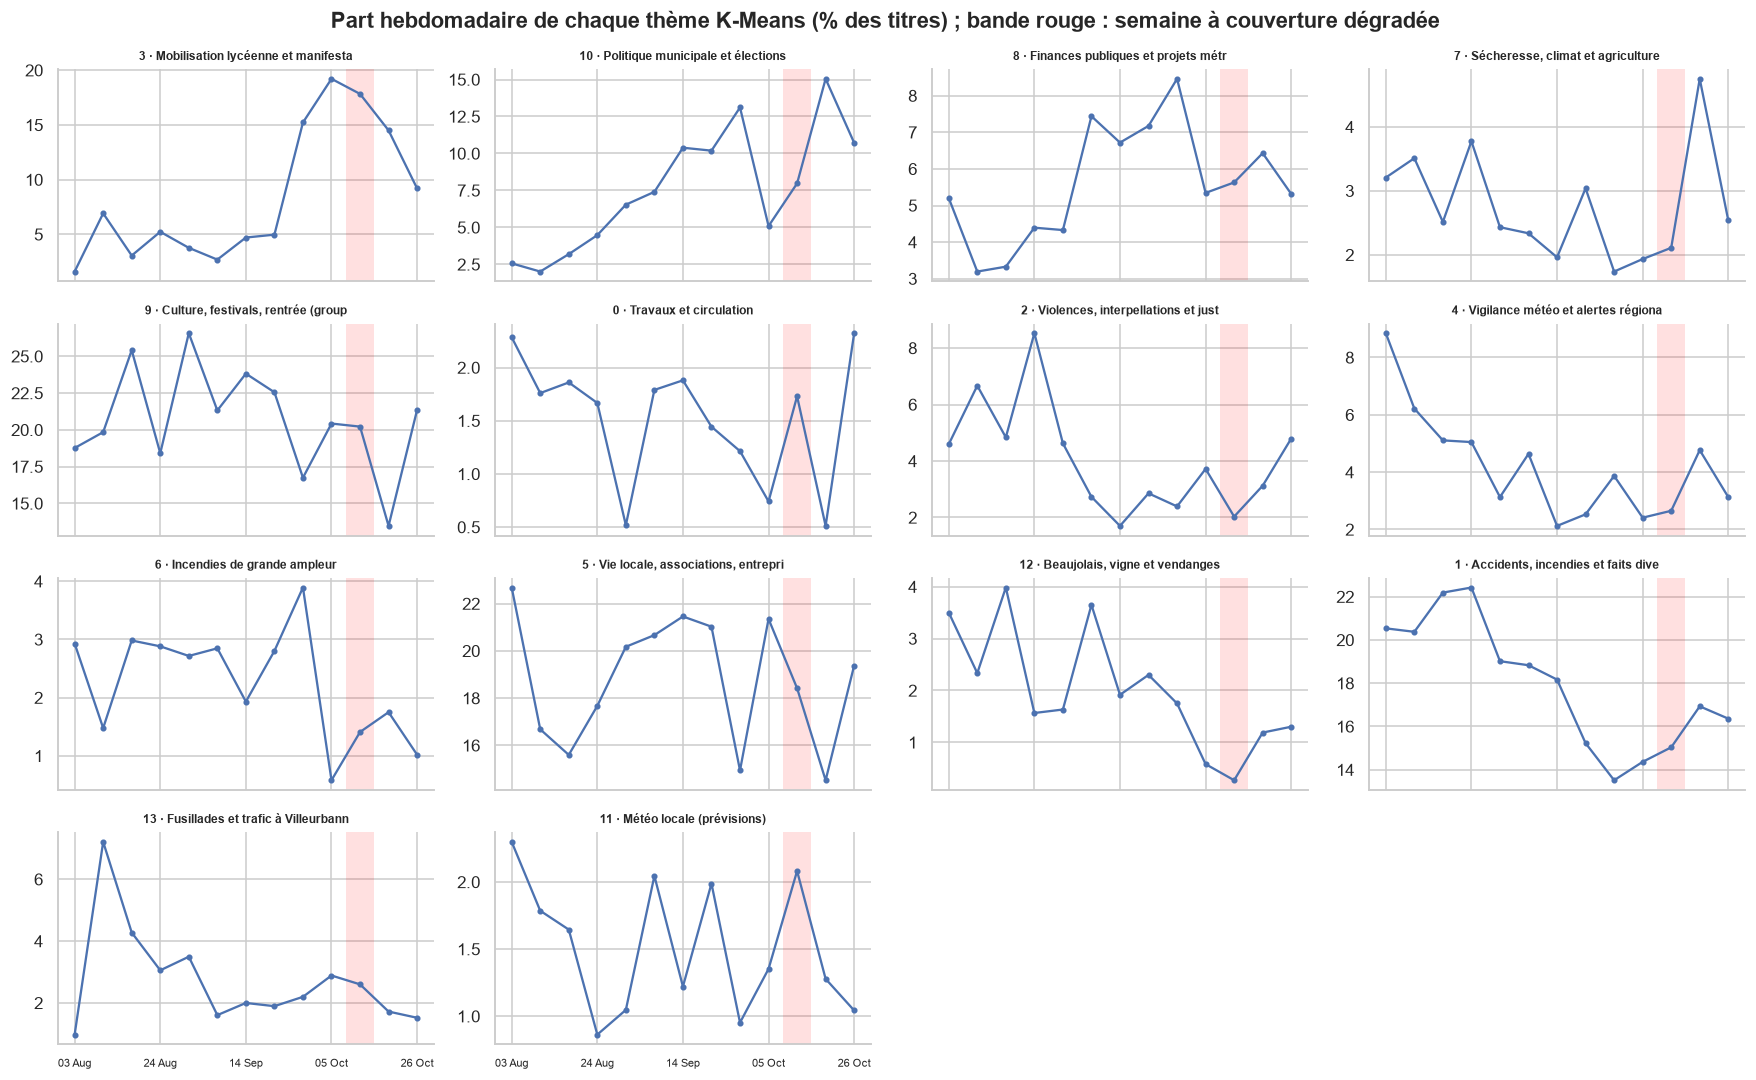

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(16, 10), sharex=True)
for ax, k in zip(axes.ravel(), trend.cluster):
    ax.plot(range(len(weeks)), p_k[:, k], marker="o", ms=3, color=sns.color_palette()[0]); ax.axvspan(LOW_W - 0.5, LOW_W + 0.5, color="red", alpha=0.12, lw=0)
    ax.set_title(f"{k} · {lab[k][:34]}", fontsize=8); ax.set_xticks(range(0, len(weeks), 3)); ax.set_xticklabels([week_labels[i] for i in range(0, len(weeks), 3)], fontsize=7)
for ax in axes.ravel()[K:]: ax.axis("off")
fig.suptitle("Part hebdomadaire de chaque thème K-Means (% des titres) ; bande rouge : semaine à couverture dégradée", fontweight="bold")
plt.tight_layout(); fig.savefig(FIG / "06_themes_series.png", bbox_inches="tight"); plt.show()

## 5. Robustesse : les résultats dépendent-ils des choix méthodologiques ?
On refait la détection en changeant un choix à la fois, et on mesure le recouvrement (indice de Jaccard) avec la configuration de référence, pour les **20 premiers termes** et pour **l'ensemble des termes détectés**. (Faire varier un seuil ne change pas le haut du classement, trié par z : seul l'ensemble détecté est informatif dans ce cas.)

In [9]:
def top_terms(**kw):
    d = kw.pop("data", df); sets_ = sets if d is df else E.term_sets(d.tokens_raw, d.tokens_lemma)
    B_, terms_ = (B, terms) if d is df else E.binary_matrix(sets_, min_df=6)
    c_, n_ = E.weekly_counts(B_, d, weeks); pi_ = E.media_weights(d)
    ev_, _ = E.detect_events(c_, n_, pi_, terms_, B_, d, weeks, **kw)
    return ev_
ref = top_terms(); ref20 = set(ref.terme.head(20))
no_low = df[~df.low_coverage_day].reset_index(drop=True)
variants = {"référence (z ≥ 4, base 4 sem., médias pondérés)": {}, "sans pondération par média (parts brutes)": {"balanced": False},
            "base de 3 semaines": {"base_weeks": 3}, "base de 6 semaines": {"base_weeks": 6}, "seuil z ≥ 3": {"z_min": 3}, "seuil z ≥ 6": {"z_min": 6},
            "au moins 1 média (pas de critère multi-médias)": {"media_min": 1}, "sans les jours à couverture dégradée": {"data": no_low}}
ref_all = set(ref.terme); res = []; cache = {}
for name, kw in variants.items():
    e = top_terms(**dict(kw)); cache[name] = e; t20, tall = set(e.terme.head(20)), set(e.terme)
    res.append({"variante": name, "termes émergents": len(e), "Jaccard du top 20": round(len(t20 & ref20) / len(t20 | ref20), 2),
                "Jaccard de l'ensemble détecté": round(len(tall & ref_all) / len(tall | ref_all), 2)})
sens = pd.DataFrame(res); sens.to_csv(TAB / "06_sensibilite.csv", index=False); display(sens)
raw20 = set(cache["sans pondération par média (parts brutes)"].terme.head(20))
print("Top 20 présents seulement SANS pondération par média :", sorted(raw20 - ref20))
print("Top 20 présents seulement AVEC pondération (référence)  :", sorted(ref20 - raw20))

,variante,termes émergents,Jaccard du top 20,Jaccard de l'ensemble détecté
0,"référence (z ≥ 4, base 4 sem., médias pondérés)",87,1.00,1.00
1,sans pondération par média (parts brutes),94,0.74,0.89
2,base de 3 semaines,79,0.74,0.77
3,base de 6 semaines,81,0.82,0.57
4,seuil z ≥ 3,126,1.00,0.69
5,seuil z ≥ 6,50,1.00,0.57
6,au moins 1 média (pas de critère multi-médias),87,1.00,1.00
7,sans les jours à couverture dégradée,86,0.82,0.97


Top 20 présents seulement SANS pondération par média : ['député', 'raphaël', 'vacance']
Top 20 présents seulement AVEC pondération (référence)  : ['manifestation', 'mobilisation lycéenne', 'raphaël arnault']


## 6. Synthèse de l'étape 6

- **Données** : 4 858 titres des trois médias principaux, 13 semaines, 1 391 termes (lemmes et bigrammes présents dans ≥ 6 titres). Avec 4 semaines de base, seules **9 semaines** (31 août – 26 octobre) sont évaluables.
- **Fréquent ≠ émergent** : la corrélation de rang entre fréquence et score d'émergence maximal est de −0,20. Les termes les plus fréquents (« homme », « Villeurbanne », « blessé », « incendie », « personne ») ont un z maximal de 1,2 à 2,6 : ils sont présents toutes les semaines. Seuls « lycéen » (106 titres, z = 24) et « manifestation » (103 titres, z = 9,9) sont à la fois fréquents et émergents, **parce que** leur fréquence provient d'un pic.
- **87 termes émergents détectés** (z ≥ 4, ≥ 6 titres, ≥ 2 médias) : 34 pics ponctuels, 27 montées durables, 26 indéterminés (pic trop près de la fin). La semaine du 19 octobre concentre le plus de détections (17), puis celle du 28 septembre (12).
- **Précision mesurée par lecture** : sur les 32 premiers termes, **31 correspondent à un événement identifiable**, un seul est un faux positif (« chef »). Ils se regroupent en 17 familles d'événements, car un événement génère plusieurs termes (« couvre-feu », « pillage », « émeute », « commerçant »…). Cette annotation est la nôtre, sans second lecteur : ce n'est pas une évaluation indépendante.
- **Les grands récits émergents** : (1) le **mouvement lycéen** (blocages et affrontements, pic le 28 septembre – 5 octobre, puis effondrement : « lycéen » passe de 6,5 % à 0,5 % des titres) ; (2) les **émeutes du 17 octobre à Lyon** (pillages, couvre-feu en Presqu'île, aides aux commerçants, « acte II » puis « acte III » des Gilets jaunes) ; (3) l'**affaire Quentin Deranque** et l'audition de Raphaël Arnault (semaine du 26 octobre) ; à quoi s'ajoutent l'attentat de Trappes, le recours contre les municipales (14 septembre), le procès Iris et Warren, le festival Lumière et les frères Coen, le Vœu des Échevins, Equita Lyon et Halloween.
- **Déclins (début → fin de période, 12 termes)** : canicule (43 → 5 titres), vigilance (40 → 8), orage, rentrée, éclipse (20 → 0), forêt, noyade, vendanges, Beaujolais, feu, et « fusillade » (20 → 1). Presque tous sont **saisonniers** : en 13 semaines, on ne distingue pas un déclin éditorial d'un cycle saisonnier.
- **Thèmes K-Means** : « mobilisation lycéenne » est en hausse (ρ = 0,71, p = 0,006, pic le 28 septembre, z = 10,3) ; « politique municipale et élections » monte régulièrement (ρ = 0,83, pente +0,83 point/semaine) mais sans pic net (z = 3,9, sous le seuil). En baisse : « accidents, incendies et faits divers du quotidien » (−0,60 point/semaine), « vigilance météo » et « Beaujolais, vendanges » (saisonniers). **Précaution** : les parts de thèmes sont en somme 100 % ; quand un thème d'actualité éclate, les autres reculent mécaniquement. La baisse des faits divers est en partie cet effet.
- **Robustesse** : sans pondération par média, le top 20 diffère de 3 termes (variantes d'un même événement : « raphaël » au lieu de « raphaël arnault ») et l'ensemble détecté recoupe à 0,89 ; sans les jours à couverture dégradée, 0,97. Une base de 3 semaines recoupe à 0,77 ; une base de 6 semaines à 0,57, **parce qu'elle réduit à 7 le nombre de semaines évaluables** et fait disparaître les premiers événements. Les seuils z ≥ 3 et z ≥ 6 donnent respectivement 126 et 50 termes, emboîtés dans la référence. Le critère « au moins 2 médias » n'a eu aucun effet ici (aucun terme à ≥ 6 titres et z ≥ 4 n'était mono-média) ; il est conservé comme garde-fou.
- **Points de vigilance** : 9 des 87 termes ont leur pic la semaine du 12 octobre (couverture dégradée du Progrès) ; ils sont marqués « confiance faible » (« vacance » et « coen » en font partie). Le z est un indice de classement, pas une p-valeur (titres corrélés, ≈ 12 500 tests). Les 13 semaines ne permettent ni de mesurer une saisonnalité, ni de valider les tendances longues.